# Commodity Price Forecasting AI Agent
## Notebook 07 - Random Forest Regression Model

### Objective

This notebook develops a Random Forest Regression model to predict silver closing prices using engineered features. The model performance is evaluated and predictions are exported for comparison with other forecasting models.

**Project:** Zetheta Project 1D

**Author:** Sanjivanee Sathe

**Date:** July 2026

In [1]:
# =====================================================
# Import Libraries
# =====================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# =====================================================
# Load Dataset
# =====================================================

silver = pd.read_csv("../outputs/feature_engineered_silver.csv")

silver.head()

,Date,Open,High,Low,Close,Adj_Close,Volume,VWAP,Returns_Pct,Log_Returns,...,Open_Close_Range,EMA_7,EMA_14,EMA_30,RSI_14,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower
0,2000-02-14,5.3331,5.3487,5.3321,5.3336,5.3336,36878,5.3382,-0.3622,-0.003628,...,-0.0005,5.330154,5.314042,5.286113,47.688518,0.026011,0.023204,5.304540,5.417420,5.191660
1,2000-02-15,5.3607,5.3662,5.3607,5.3608,5.3608,23437,5.3626,0.5102,0.005089,...,-0.0001,5.337816,5.320276,5.290931,50.009053,0.027479,0.024059,5.306630,5.422154,5.191106
2,2000-02-16,5.3526,5.4488,5.3185,5.3539,5.3539,38455,5.3737,-0.1296,-0.001297,...,-0.0013,5.341837,5.324760,5.294994,68.792030,0.027766,0.024800,5.306575,5.422003,5.191147
3,2000-02-17,5.3307,5.4092,5.2876,5.3405,5.3405,19680,5.3458,-0.2504,-0.002507,...,-0.0098,5.341503,5.326858,5.297930,66.602363,0.026605,0.025161,5.307905,5.424297,5.191513
4,2000-02-18,5.2893,5.2949,5.2893,5.2896,5.2896,24962,5.2913,-0.9527,-0.009573,...,-0.0003,5.328527,5.321890,5.297392,58.790252,0.021332,0.024395,5.308670,5.424331,5.193009


In [4]:
# =====================================================
# Feature Selection
# =====================================================

features = [

"Open",
"High",
"Low",
"Volume",

"Lag_1",
"Lag_3",
"Lag_7",
"Lag_14",
"Lag_30",

"MA_7",
"MA_14",
"MA_30",

"EMA_7",
"EMA_14",
"EMA_30",

"Volatility_7",
"Volatility_14",

"RSI_14",

"MACD"

]

X = silver[features]

y = silver["Close"]

In [5]:
# =====================================================
# Train Test Split
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(

X,

y,

test_size=0.20,

shuffle=False

)

In [6]:
# =====================================================
# Random Forest
# =====================================================

model = RandomForestRegressor(

n_estimators=300,

max_depth=10,

random_state=42,

n_jobs=-1

)

model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [7]:
# =====================================================
# Prediction
# =====================================================

predictions = model.predict(X_test)

In [8]:
# =====================================================
# Evaluation
# =====================================================

mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(mean_squared_error(y_test, predictions))

r2 = r2_score(y_test, predictions)

print("MAE :", round(mae,4))

print("RMSE :", round(rmse,4))

print("R² :", round(r2,4))

MAE : 0.0587
RMSE : 0.088
R² : 0.9996


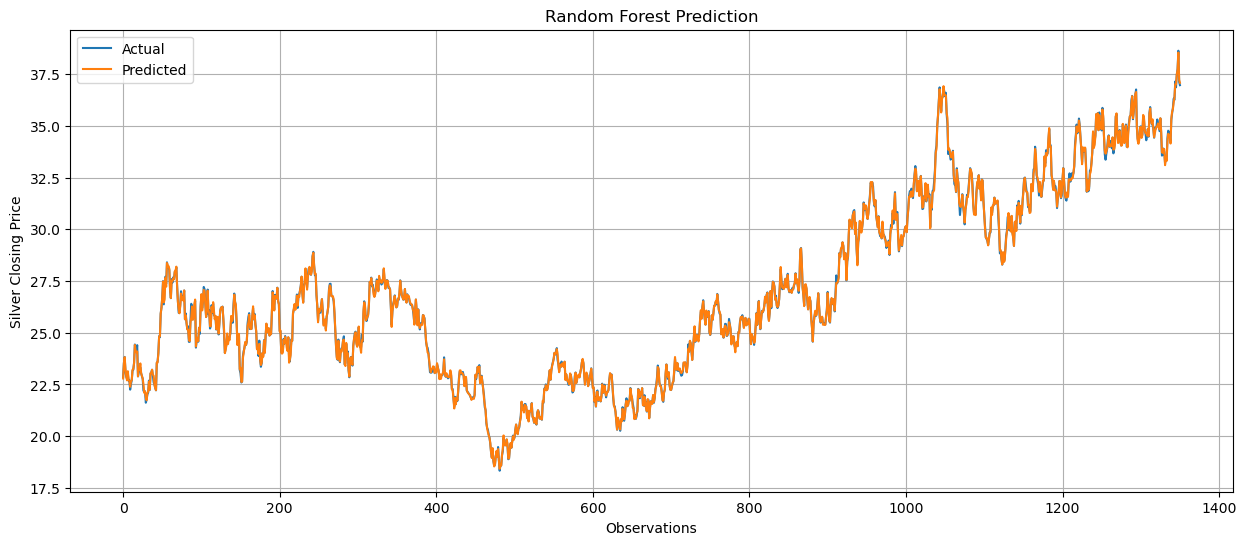

In [9]:
# =====================================================
# Actual vs Predicted
# =====================================================

plt.figure(figsize=(15,6))

plt.plot(y_test.values,label="Actual")

plt.plot(predictions,label="Predicted")

plt.title("Random Forest Prediction")

plt.xlabel("Observations")

plt.ylabel("Silver Closing Price")

plt.legend()

plt.grid(True)

plt.show()

In [10]:
# =====================================================
# Feature Importance
# =====================================================

importance = pd.DataFrame({

"Feature":features,

"Importance":model.feature_importances_

})

importance = importance.sort_values(

by="Importance",

ascending=False

)

display(importance)

,Feature,Importance
1,High,3.919562e-01
2,Low,3.505698e-01
0,Open,2.560478e-01
4,Lag_1,1.298649e-03
12,EMA_7,3.179242e-05
13,EMA_14,3.001922e-05
9,MA_7,2.622986e-05
10,MA_14,1.039493e-05
14,EMA_30,1.010702e-05
5,Lag_3,3.699806e-06


In [11]:
# =====================================================
# Save Predictions
# =====================================================

results = pd.DataFrame({

"Actual":y_test,

"Predicted":predictions

})

results.to_csv(

"../outputs/random_forest_predictions.csv",

index=False

)

print("Random Forest predictions saved successfully.")

Random Forest predictions saved successfully.


# Conclusion

The Random Forest Regression model was trained using the engineered features. Model performance was evaluated using MAE, RMSE, and R². The predictions were exported for comparison with other forecasting models.